In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "data" / "datos_limpios.csv"
MODELS_DIR = BASE_DIR / "models"
RESULTS_DIR = BASE_DIR / "resultados"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

columnas = [
    "AGE", "GENDER", "DURATION OF FEVER", "HEADACHE", "MYALGIA",
    "ABDOMINAL PAIN", "RASH", "VOMITING", "BREATHLESSNESS", "BLEEDING",
    "BP AT ADMISSION", "ORGANOMEGALY", "HB", "CREATININE",
    "PCV_ALTO", "PLAQUETAS_BAJAS", "WBC_ALTO", "ALT_ALTO"
]
objetivo = "GROUPS: DENGUE FEVER OR COMPLICATED DENGUE"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró {DATA_PATH}. Ejecuta el notebook desde la carpeta principal del proyecto."
    )

df = pd.read_csv(DATA_PATH)
print("Dimensiones del conjunto de datos:", df.shape)

requeridas = columnas + [objetivo]
faltantes = [c for c in requeridas if c not in df.columns]
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {faltantes}")
if df[requeridas].isna().any().any():
    raise ValueError("Hay valores faltantes en las columnas utilizadas.")

X = df[columnas].copy()
y = df[objetivo].astype(int).copy()
if set(y.unique()) != {0, 1}:
    raise ValueError("La variable objetivo debe estar codificada como 0 y 1.")

print("Variables predictoras:", X.shape[1])
print("Total de pacientes:", len(X))
display(y.value_counts().sort_index().rename(
    index={0: "Dengue no complicado", 1: "Dengue complicado"}
).to_frame("Cantidad"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Pacientes para entrenamiento:", len(X_train))
print("Pacientes para prueba:", len(X_test))

Dimensiones del conjunto de datos: (302, 24)
Variables predictoras: 18
Total de pacientes: 302


,Cantidad
GROUPS: DENGUE FEVER OR COMPLICATED DENGUE,
Dengue no complicado,239
Dengue complicado,63


Pacientes para entrenamiento: 241
Pacientes para prueba: 61


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

print("Entrenando regresión logística...")
modelo.fit(X_train, y_train)
print("Entrenamiento completado.")

Entrenando regresión logística...
Entrenamiento completado.


,Resultado
Exactitud,0.8525
Precisión,0.5909
Sensibilidad,1.0000
F1-score,0.7429
AUC,0.9696


REPORTE DE CLASIFICACIÓN
                      precision    recall  f1-score   support

Dengue no complicado       1.00      0.81      0.90        48
   Dengue complicado       0.59      1.00      0.74        13

            accuracy                           0.85        61
           macro avg       0.80      0.91      0.82        61
        weighted avg       0.91      0.85      0.86        61

MATRIZ DE CONFUSIÓN
[[39  9]
 [ 0 13]]


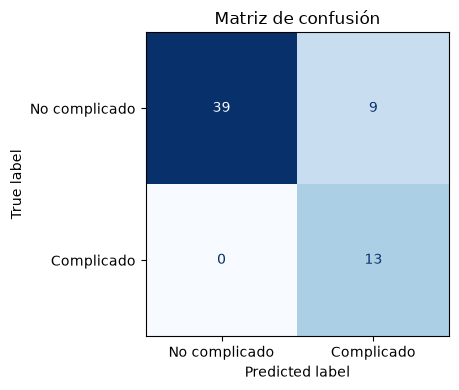

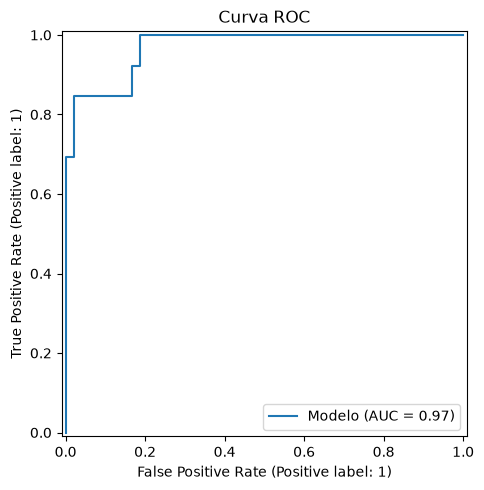

In [6]:
predicciones = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)[:, 1]

metricas = {
    "Exactitud": accuracy_score(y_test, predicciones),
    "Precisión": precision_score(y_test, predicciones, zero_division=0),
    "Sensibilidad": recall_score(y_test, predicciones, zero_division=0),
    "F1-score": f1_score(y_test, predicciones, zero_division=0),
    "AUC": roc_auc_score(y_test, probabilidades)
}
tabla_metricas = pd.DataFrame(
    [metricas]
).T.rename(columns={0: "Resultado"})

tabla_metricas["Resultado"] = tabla_metricas["Resultado"].round(4)

display(tabla_metricas)

print("REPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test, predicciones,
    target_names=["Dengue no complicado", "Dengue complicado"],
    zero_division=0
))

matriz = confusion_matrix(y_test, predicciones, labels=[0, 1])
print("MATRIZ DE CONFUSIÓN")
print(matriz)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No complicado", "Complicado"]
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "matriz_confusion_modelo.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, probabilidades, ax=ax, name="Modelo")
ax.set_title("Curva ROC")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "curva_roc_modelo.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
ruta_modelo = MODELS_DIR / "modelo_logistico.pkl"
joblib.dump(modelo, ruta_modelo)
print("Modelo guardado en:", ruta_modelo)

Modelo guardado en: c:\Users\mcgre\Desktop\Dengue_m3\models\modelo_logistico.pkl
